# Fine-tune ViT5

Luồng huấn luyện chính: dữ liệu đã chuẩn bị → tokenizer/DataLoader → ViT5-Base → optimizer → từng epoch → validation → last/best → loss → sinh tóm tắt → so sánh greedy/beam trên validation.


### 1. Môi trường và phiên bản mã

In [1]:
from pathlib import Path
from google.colab import drive

resume_run_id = ""

drive.mount("/content/drive")
drive_root = Path("/content/drive/MyDrive/vietnamese-summarization")

if not drive_root.is_dir():
    raise RuntimeError("Lỗi: Không tìm thấy thư mục dự án trên Drive.")


Mounted at /content/drive


In [2]:
import os
import sys
import json
import subprocess

repo_url = "https://github.com/MD1809/vietnamese-summarization.git"
repo_dir = Path("/content/vietnamese-summarization")
target_commit = ""

if not repo_dir.exists():
    subprocess.run(["git", "clone", repo_url, str(repo_dir)], check=True)

remote_result = subprocess.run(
    ["git", "remote", "get-url", "origin"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

if remote_result.stdout.strip() != repo_url:
    raise RuntimeError("Lỗi: Repository không đúng dự án.")

status_result = subprocess.run(
    ["git", "status", "--porcelain"],
    cwd=repo_dir,
    capture_output=True,
    text=True,
    check=True,
)

if status_result.stdout.strip() != "":
    raise RuntimeError("Lỗi: Repository còn thay đổi. Hãy dùng runtime mới.")

subprocess.run(["git", "fetch", "origin"], cwd=repo_dir, check=True)

if target_commit == "":
    if resume_run_id != "":
        profile_path = drive_root / "outputs" / resume_run_id / "config.json"
        saved_profile = json.loads(profile_path.read_text(encoding="utf-8"))
        target_commit = saved_profile["source"]["git_commit"]
    else:
        commit_result = subprocess.run(
            ["git", "rev-parse", "origin/main"],
            cwd=repo_dir,
            capture_output=True,
            text=True,
            check=True,
        )
        target_commit = commit_result.stdout.strip()

subprocess.run(
    ["git", "checkout", "--detach", target_commit],
    cwd=repo_dir,
    check=True,
)

os.chdir(repo_dir)

if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))

print("Commit sử dụng:", target_commit)


Commit sử dụng: b5cb961ed118f014d8fc4c5c5af607d429361949


In [3]:
%pip uninstall -y -q diffusers torchvision timm fastai
%pip install -q "jedi==0.20.1"
%pip install -q -r /content/vietnamese-summarization/requirements.txt
%pip check


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
No broken requirements found.


In [4]:
import gc
import csv
import math
import time
import torch
import src.train
import src.tokenization
from src.utils import load_generation_config, load_train_config, set_seed

config_path = repo_dir / "configs" / "train.json"
train_config = load_train_config(config_path)
generation_config = load_generation_config(
    repo_dir / "configs" / "generation.json"
)

if not torch.cuda.is_available():
    raise RuntimeError("Lỗi: Cần GPU để chạy notebook huấn luyện.")

set_seed(train_config["seed"])

print(json.dumps(
    {
        "seed": train_config["seed"],
        "max_source_length": train_config["max_source_length"],
        "max_target_length": train_config["max_target_length"],
        "batch_size": train_config["batch_size"],
        "gradient_accumulation_steps": train_config["gradient_accumulation_steps"],
        "num_epochs": train_config["num_epochs"],
        "generation_config": generation_config,
    },
    ensure_ascii=False,
    indent=2,
))

print("GPU:", torch.cuda.get_device_name(0))


{
  "seed": 42,
  "max_source_length": 1024,
  "max_target_length": 128,
  "batch_size": 1,
  "gradient_accumulation_steps": 8,
  "num_epochs": 10,
  "generation_config": {
    "num_beams": 4,
    "max_new_tokens": 128,
    "do_sample": false
  }
}
GPU: Tesla T4


## 2. Dữ liệu, model và optimizer

In [5]:
tokenized_splits, tokenizer = src.tokenization.tokenize_train_validation(
    drive_root,
    config_path,
)

data_loaders = src.tokenization.create_train_validation_loaders(
    tokenized_splits,
    tokenizer,
    config_path,
)

print("Train:", len(tokenized_splits["train"]))
print("Validation:", len(tokenized_splits["validation"]))


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/820k [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


Tokenizing train:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing validation:   0%|          | 0/201 [00:00<?, ? examples/s]

Train: 2000
Validation: 201


In [6]:
set_seed(train_config["seed"])

if resume_run_id == "":
    run_profile = src.train.create_training_run(
        repo_dir,
        drive_root,
        allow_uncommitted=False,
    )
    model = src.train.load_vit5_model(config_path)
    optimizer = src.train.create_optimizer(model, config_path)
    progress = None
else:
    if Path(resume_run_id).name != resume_run_id or resume_run_id in [".", ".."]:
        raise RuntimeError("Lỗi: Run ID không được chứa đường dẫn.")

    profile_path = drive_root / "outputs" / resume_run_id / "config.json"
    run_profile = json.loads(profile_path.read_text(encoding="utf-8"))

    if run_profile["run_id"] != resume_run_id:
        raise RuntimeError("Lỗi: Hồ sơ không đúng run cần tiếp tục.")

    if run_profile["source"]["git_commit"] != target_commit:
        raise RuntimeError(
            "Lỗi: Resume cần đúng commit của run: "
            + run_profile["source"]["git_commit"]
        )

    model, tokenizer, optimizer, progress, resume_report = (
        src.train.load_last_checkpoint(
            run_profile["paths"]["checkpoint_dir"],
            data_loaders["train"],
            config_path,
        )
    )
    print("Epoch đã hoàn thành:", progress["completed_epochs"])
    print("Global step:", progress["global_step"])

print("Run huấn luyện:", run_profile["run_id"])

output_dir = Path(run_profile["paths"]["output_dir"])
checkpoint_dir = Path(run_profile["paths"]["checkpoint_dir"])
print("Output:", output_dir)
print("Checkpoint:", checkpoint_dir)


config.json:   0%|          | 0.00/702 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/904M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/904M [00:00<?, ?B/s]

Run huấn luyện: vit5_finetuning_20261113_071230_169031
Output: /content/drive/.shortcut-targets-by-id/1pYCC4s6c4UIpyf6pvB0tIsvIlJTL48zs/vietnamese-summarization/outputs/vit5_finetuning_20261113_071230_169031
Checkpoint: /content/drive/.shortcut-targets-by-id/1pYCC4s6c4UIpyf6pvB0tIsvIlJTL48zs/vietnamese-summarization/checkpoints/vit5_finetuning_20261113_071230_169031


## 3. Vòng lặp epoch thực sự huấn luyện


In [7]:
if run_profile["train_config"] != train_config:
    raise RuntimeError("Lỗi: Cấu hình run không khớp cấu hình hiện tại.")

source_state, source_patch, source_snapshots = src.train.collect_run_source(
    repo_dir,
    allow_uncommitted=False,
)

if source_state["git_commit"] != run_profile["source"]["git_commit"]:
    raise RuntimeError("Lỗi: Phiên bản mã nguồn đã thay đổi.")

if run_profile["source_changes"]["patch_file"] is not None:
    raise RuntimeError("Lỗi: Run dùng bản vá phát triển; cần khôi phục đúng source trước khi resume.")

if run_profile["source_changes"]["untracked_snapshot_files"]:
    raise RuntimeError("Lỗi: Run dùng source snapshot; cần khôi phục đúng source trước khi resume.")

for name in ["last_pending", "last_previous", "best_pending", "best_previous"]:
    if (checkpoint_dir / name).exists():
        raise RuntimeError("Lỗi: Còn checkpoint tạm; cần kiểm tra trước khi huấn luyện.")

if progress is None:
    if (checkpoint_dir / "last").exists() or (checkpoint_dir / "best").exists():
        raise RuntimeError("Lỗi: Run mới không được dùng lại thư mục checkpoint cũ.")
    if len(optimizer.state) != 0 or (output_dir / "training_history.csv").exists():
        raise RuntimeError("Lỗi: Run mới cần optimizer và lịch sử mới.")
    progress = {"completed_epochs": 0, "global_step": 0, "training_history": []}

history = list(progress["training_history"])
completed_epochs = progress["completed_epochs"]
updates_per_epoch = (
    len(data_loaders["train"]) + train_config["gradient_accumulation_steps"] - 1
) // train_config["gradient_accumulation_steps"]

if len(history) != completed_epochs or not 0 <= completed_epochs <= train_config["num_epochs"]:
    raise RuntimeError("Lỗi: Lịch sử không khớp số epoch đã hoàn thành.")

if progress["global_step"] != completed_epochs * updates_per_epoch:
    raise RuntimeError("Lỗi: Global step không khớp tiến độ.")

for index, row in enumerate(history, 1):
    if row["epoch"] != index or row["global_step"] != index * updates_per_epoch:
        raise RuntimeError("Lỗi: Lịch sử epoch không liên tục.")

validation_ids = []

for sample in tokenized_splits["validation"]:
    validation_ids.append(sample["id"])

train_ids = []

for sample in tokenized_splits["train"]:
    train_ids.append(sample["id"])

if len(train_ids) != run_profile["data"]["train_sample_count"]:
    raise RuntimeError("Lỗi: Số mẫu train không khớp hồ sơ run.")

if len(validation_ids) != run_profile["data"]["validation_sample_count"]:
    raise RuntimeError("Lỗi: Số mẫu validation không khớp hồ sơ run.")

if set(train_ids).intersection(validation_ids):
    raise RuntimeError("Lỗi: Train và validation trùng ID.")

src.train.write_training_history(output_dir, history)
started_at = time.perf_counter()
early_stopping_settings = train_config.get("early_stopping")
early_stopping_state = progress.get("early_stopping")
if early_stopping_settings is not None and early_stopping_state is None:
    # Reconstruct state when resuming a checkpoint without the stored counter.
    for row in history:
        early_stopping_state, _ = src.train.early_stopping(
            early_stopping_state, row["validation_loss"], early_stopping_settings,
        )
stopped_early = (
    early_stopping_settings is not None
    and early_stopping_state is not None
    and early_stopping_state["epochs_without_improvement"] >= early_stopping_settings["patience"]
)

for epoch_index in range(completed_epochs, train_config["num_epochs"]):
    if stopped_early:
        break
    print("Bắt đầu epoch:", epoch_index + 1, flush=True)

    training = src.train.train_epoch(
        model,
        data_loaders["train"],
        optimizer,
        progress["global_step"],
        config_path,
    )

    torch.cuda.synchronize()
    validation_started_at = time.perf_counter()
    validation = src.train.validate_model(model, data_loaders["validation"], validation_ids)
    torch.cuda.synchronize()
    validation_seconds = time.perf_counter() - validation_started_at

    if not math.isfinite(training["train_loss"]) or not math.isfinite(validation["validation_loss"]):
        raise RuntimeError("Lỗi: Loss không hữu hạn.")

    progress["completed_epochs"] = epoch_index + 1
    progress["global_step"] = training["global_step"]
    progress, best_decision = src.train.update_best_checkpoint(
        model, tokenizer, checkpoint_dir, progress, validation, config_path,
    )

    history.append({
        "epoch": epoch_index + 1,
        "global_step": training["global_step"],
        "train_loss": training["train_loss"],
        "validation_loss": validation["validation_loss"],
        "train_sample_count": training["train_sample_count"],
        "validation_sample_count": validation["sample_count"],
        "train_valid_target_tokens": training["train_valid_target_tokens"],
        "validation_valid_target_tokens": validation["valid_target_token_count"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "train_seconds": training["train_seconds"],
        "validation_seconds": validation_seconds,
        "epoch_compute_seconds": training["train_seconds"] + validation_seconds,
    })
    progress["training_history"] = list(history)
    early_stopping_state, stopped_early = src.train.early_stopping(
        early_stopping_state, validation["validation_loss"], early_stopping_settings,
    )
    if early_stopping_settings is not None:
        progress["early_stopping"] = early_stopping_state

    src.train.save_last_checkpoint(
        model, tokenizer, optimizer, checkpoint_dir, progress,
        data_loaders["train"], config_path,
    )
    src.train.write_training_history(output_dir, history)

    print(
        "Epoch:", epoch_index + 1,
        "Train loss:", training["train_loss"],
        "Validation loss:", validation["validation_loss"],
        "Cập nhật best:", best_decision["updated"],
        flush=True,
    )

    if stopped_early:
        print(
            "Dừng sớm sau epoch:", epoch_index + 1,
            "Số epoch không cải thiện:", early_stopping_state["epochs_without_improvement"],
            "Best epoch:", progress["best_epoch"],
            flush=True,
        )
        break

training_summary = {
    "run_id": run_profile["run_id"],
    "run_status": "completed",
    "stopped_early": stopped_early,
    "stop_reason": "early_stopping" if stopped_early else "max_epochs",
    "early_stopping": early_stopping_state,
    "inference_checkpoint_dir": str(checkpoint_dir / "best"),
    "completed_epochs": progress["completed_epochs"],
    "global_step": progress["global_step"],
    "history": history,
    "best_epoch": progress["best_epoch"],
    "best_global_step": progress["best_global_step"],
    "best_validation_loss": progress["best_validation_loss"],
    "checkpoint_dir": str(checkpoint_dir),
    "history_file": str(output_dir / "training_history.csv"),
    "current_invocation_seconds": time.perf_counter() - started_at,
    "resume_boundary": "end_of_epoch",
    "test_content_read": False,
    "training_entrypoint": "epoch loop in vietnamese_summarization_train.ipynb",
}

summary_path = output_dir / "training_summary.json"
summary_path.write_text(json.dumps(training_summary, ensure_ascii=False, indent=2), encoding="utf-8")

if json.loads(summary_path.read_text(encoding="utf-8")) != training_summary:
    raise RuntimeError("Lỗi: Summary đọc lại không khớp.")

del optimizer
del model
gc.collect()
torch.cuda.empty_cache()
print("Hoàn tất run:", training_summary["run_id"])
print("Best epoch:", training_summary["best_epoch"])
print("Best validation loss:", training_summary["best_validation_loss"])


Bắt đầu epoch: 1
Global step: 25 Mẫu đã học: 200 Train loss: 2.9444180689331385
Global step: 50 Mẫu đã học: 400 Train loss: 2.70541416069942
Global step: 75 Mẫu đã học: 600 Train loss: 2.6208257625687796
Global step: 100 Mẫu đã học: 800 Train loss: 2.5893982825823496
Global step: 125 Mẫu đã học: 1000 Train loss: 2.5328364481825854
Global step: 150 Mẫu đã học: 1200 Train loss: 2.492963695114299
Global step: 175 Mẫu đã học: 1400 Train loss: 2.4559891563251917
Global step: 200 Mẫu đã học: 1600 Train loss: 2.4423150496576405
Global step: 225 Mẫu đã học: 1800 Train loss: 2.4237861990677105
Global step: 250 Mẫu đã học: 2000 Train loss: 2.3985432561912696
Validation đã xử lý số batch: 50
Validation đã xử lý số batch: 100
Validation đã xử lý số batch: 150
Validation đã xử lý số batch: 200
Epoch: 1 Train loss: 2.3985432561912696 Validation loss: 2.115507181829727 Cập nhật best: True
Bắt đầu epoch: 2
Global step: 275 Mẫu đã học: 200 Train loss: 1.9424896126385887
Global step: 300 Mẫu đã học: 400

## 4. Loss và phân tích


In [8]:
report_run_id = run_profile["run_id"]
log_dir = output_dir

summary_path = log_dir / "training_summary.json"
history_path = log_dir / "training_history.csv"

analysis_summary = json.loads(summary_path.read_text(encoding="utf-8"))

if analysis_summary["run_id"] != report_run_id:
    raise RuntimeError("Lỗi: Summary không thuộc run cần phân tích.")

with history_path.open(encoding="utf-8", newline="") as history_file:
    history_rows = list(csv.DictReader(history_file))

if len(history_rows) != len(analysis_summary["history"]):
    raise RuntimeError("Lỗi: CSV và summary khác số epoch.")

for actual, expected in zip(history_rows, analysis_summary["history"]):
    for key in expected:
        if actual[key] != str(expected[key]):
            raise RuntimeError("Lỗi: CSV và summary không khớp tại " + key)

epochs = []
train_losses = []
validation_losses = []

for row in history_rows:
    epochs.append(int(row["epoch"]))
    train_losses.append(float(row["train_loss"]))
    validation_losses.append(float(row["validation_loss"]))

best_epoch = analysis_summary["best_epoch"]
best_loss = analysis_summary["best_validation_loss"]

if best_epoch not in epochs or best_loss != min(validation_losses):
    raise RuntimeError("Lỗi: Thông tin best không khớp lịch sử loss.")

if validation_losses[epochs.index(best_epoch)] != best_loss:
    raise RuntimeError("Lỗi: Best epoch không khớp validation loss.")

print("Run phân tích:", report_run_id)
print("Epoch | Train loss | Validation loss")

for index in range(len(epochs)):
    print(
        epochs[index],
        "|",
        format(train_losses[index], ".6f"),
        "|",
        format(validation_losses[index], ".6f"),
    )

print("Best epoch:", best_epoch)
print("Best validation loss:", best_loss)


Run phân tích: vit5_finetuning_20261113_071230_169031
Epoch | Train loss | Validation loss
1 | 2.398543 | 2.115507
2 | 1.887079 | 2.105863
3 | 1.563590 | 2.193034
4 | 1.312433 | 2.255782
5 | 1.107884 | 2.414947
6 | 0.930741 | 2.625401
7 | 0.793361 | 2.774798
8 | 0.689305 | 2.875101
9 | 0.592972 | 3.070986
10 | 0.520566 | 3.317988
Best epoch: 2
Best validation loss: 2.1058625596091947


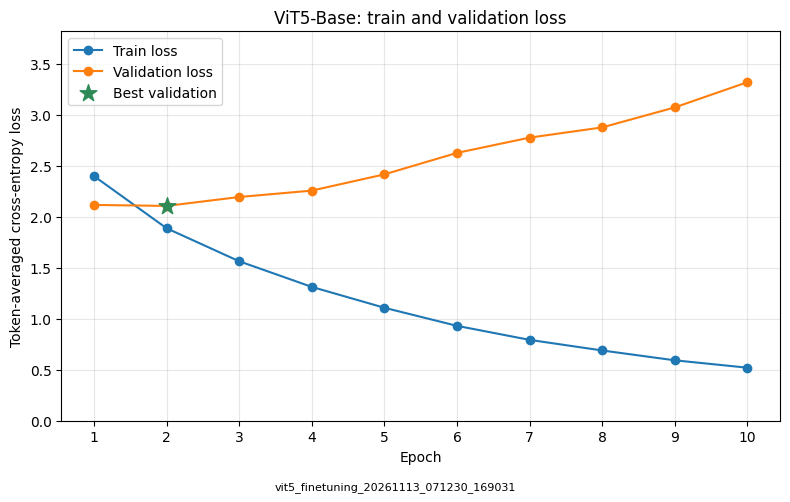

Biểu đồ: /content/drive/.shortcut-targets-by-id/1pYCC4s6c4UIpyf6pvB0tIsvIlJTL48zs/vietnamese-summarization/outputs/vit5_finetuning_20261113_071230_169031/figures/training_loss.png


In [9]:
import matplotlib.pyplot as plt

analysis_output_dir = output_dir
figure_dir = analysis_output_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)
plot_path = figure_dir / "training_loss.png"

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(epochs, train_losses, marker="o", label="Train loss")
ax.plot(epochs, validation_losses, marker="o", label="Validation loss")
ax.scatter(
    [best_epoch],
    [best_loss],
    color="seagreen",
    marker="*",
    s=160,
    zorder=5,
    label="Best validation",
)

ax.set_title("ViT5-Base: train and validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Token-averaged cross-entropy loss")
ax.set_xticks(epochs)
ax.set_ylim(0, max(train_losses + validation_losses) * 1.15)
ax.grid(True, alpha=0.3)
ax.legend()

fig.text(0.5, 0.01, report_run_id, ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.03, 1, 1])
fig.savefig(plot_path, dpi=200, facecolor="white")
plt.show()

print("Biểu đồ:", plot_path)


In [10]:
from google.colab import files

analysis_lines = [
    "# Phân tích kết quả huấn luyện",
    "",
    "- Run ID: " + report_run_id,
    "- Nguồn: training_history.csv và training_summary.json của đúng run.",
    "- Best epoch: " + str(best_epoch),
    "- Best global step: " + str(analysis_summary["best_global_step"]),
    "- Best validation loss: " + str(best_loss),
    "- Biểu đồ: [training_loss.png](figures/training_loss.png).",
    "",
    "| Epoch | Train loss | Validation loss |",
    "| --- | --- | --- |",
]

for index in range(len(epochs)):
    analysis_lines.append(
        "| " + str(epochs[index])
        + " | " + format(train_losses[index], ".6f")
        + " | " + format(validation_losses[index], ".6f") + " |"
    )

analysis_lines.append("")

if train_losses[-1] < train_losses[0] and validation_losses[-1] > best_loss:
    analysis_lines.append(
        "Train loss giảm nhưng validation loss ở epoch cuối cao hơn mức tốt nhất. "
        "Đây là dấu hiệu học quá sát train; giữ checkpoint có validation loss nhỏ nhất."
    )
else:
    analysis_lines.append(
        "Chọn checkpoint bằng validation loss nhỏ nhất trong các epoch đã lưu."
    )

analysis_lines.extend([
    "",
    "Loss được tổng hợp theo token đích hợp lệ, bỏ qua nhãn padding -100. "
    "Loss thấp không bảo đảm mọi bản tóm tắt đều đúng hoặc không lặp; "
    "đọc kết quả ROUGE và phân tích lỗi để đánh giá đầy đủ hơn.",
    "",
    "- Số liệu được tạo bởi luồng huấn luyện/resume của chính run này.",
    "- Bảng trên được tính từ log đã lưu, không thay đổi trọng số hoặc dữ liệu test.",
])

analysis_text = "\n".join(analysis_lines) + "\n"
analysis_path = analysis_output_dir / "training_analysis.md"
analysis_path.write_text(analysis_text, encoding="utf-8")

if analysis_path.read_text(encoding="utf-8") != analysis_text:
    raise RuntimeError("Lỗi: File phân tích đọc lại không khớp.")

print(analysis_text)
print("Phân tích:", analysis_path)

import shutil

training_archive = shutil.make_archive(
    str(analysis_output_dir) + "_training_results",
    "zip",
    root_dir=analysis_output_dir,
)
print("Bản sao hồ sơ và kết quả huấn luyện:", training_archive)
files.download(training_archive)


# Phân tích kết quả huấn luyện

- Run ID: vit5_finetuning_20261113_071230_169031
- Nguồn: training_history.csv và training_summary.json của đúng run.
- Best epoch: 2
- Best global step: 500
- Best validation loss: 2.1058625596091947
- Biểu đồ: [training_loss.png](figures/training_loss.png).

| Epoch | Train loss | Validation loss |
| --- | --- | --- |
| 1 | 2.398543 | 2.115507 |
| 2 | 1.887079 | 2.105863 |
| 3 | 1.563590 | 2.193034 |
| 4 | 1.312433 | 2.255782 |
| 5 | 1.107884 | 2.414947 |
| 6 | 0.930741 | 2.625401 |
| 7 | 0.793361 | 2.774798 |
| 8 | 0.689305 | 2.875101 |
| 9 | 0.592972 | 3.070986 |
| 10 | 0.520566 | 3.317988 |

Train loss giảm nhưng validation loss ở epoch cuối cao hơn mức tốt nhất. Đây là dấu hiệu học quá sát train; giữ checkpoint có validation loss nhỏ nhất.

Loss được tổng hợp theo token đích hợp lệ, bỏ qua nhãn padding -100. Loss thấp không bảo đảm mọi bản tóm tắt đều đúng hoặc không lặp; đọc kết quả ROUGE và phân tích lỗi để đánh giá đầy đủ hơn.

- Số liệu được tạ

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>